Pasta de saída: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/04_K-MODE

DataFrames disponíveis:
0 - df: 118,036 linhas x 39 colunas

Base selecionada: df
Dimensões: (118036, 39)

Dimensões de X: (118036, 39)
Número de variáveis: 39
Número de registros: 118036
Executando K-Modes para K=2...
Executando K-Modes para K=3...
Executando K-Modes para K=4...
Executando K-Modes para K=5...
Executando K-Modes para K=6...
Executando K-Modes para K=7...
Executando K-Modes para K=8...


,K,Custo,Menor_cluster,Maior_cluster,Menor_cluster_%,Clusters_vazios
0,2,1349603.0,40450,77586,34.27,0
1,3,1287080.0,29959,50763,25.38,0
2,4,1251856.0,25953,35373,21.99,0
3,5,1236748.0,18887,32386,16.00,0
4,6,1217526.0,12063,24431,10.22,0
5,7,1197293.0,10311,27043,8.74,0
6,8,1173337.0,9595,22777,8.13,0


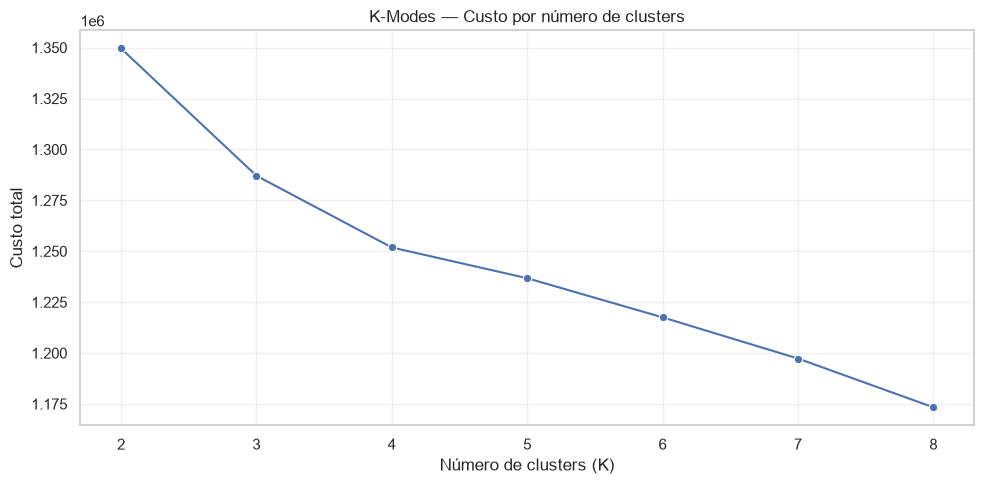


Diagnóstico concluído.
Arquivos salvos em:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/04_K-MODE

Arquivos gerados:
- diagnostico_K.csv
- grafico_cotovelo_KModes.png
- matriz_categorica_KModes.parquet


In [13]:

# ============================================================
# K-MODES — DIAGNÓSTICO DE K E EXPORTAÇÃO DOS RESULTADOS
# Projeto: Suicidio_adolescentes_Brasil
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from kmodes.kmodes import KModes

# ------------------------------------------------------------
# 1. DEFINIR PASTA DE SAÍDA
# ------------------------------------------------------------

PASTA_SAIDA = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/04_K-MODE"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

print("Pasta de saída:", PASTA_SAIDA)

# ------------------------------------------------------------
# 2. IDENTIFICAR DATAFRAMES DISPONÍVEIS
# ------------------------------------------------------------

dataframes = {
    nome: objeto
    for nome, objeto in globals().copy().items()
    if isinstance(objeto, pd.DataFrame)
    and not nome.startswith("_")
}

if not dataframes:
    raise RuntimeError(
        "Nenhum DataFrame encontrado. Execute primeiro "
        "as células que carregam e preparam a base."
    )

print("\nDataFrames disponíveis:")

nomes_df = list(dataframes.keys())

for i, nome in enumerate(nomes_df):
    print(
        f"{i} - {nome}: "
        f"{dataframes[nome].shape[0]:,} linhas x "
        f"{dataframes[nome].shape[1]:,} colunas"
    )

# ------------------------------------------------------------
# 3. SELECIONAR A BASE PREPARADA
# ------------------------------------------------------------

# Altere o número abaixo após conferir a lista impressa.
# Escolha o DataFrame que contém somente as variáveis
# selecionadas para a clusterização.

INDICE_BASE = 0

if INDICE_BASE not in range(len(nomes_df)):
    raise ValueError("Índice de base inválido.")

NOME_BASE = nomes_df[INDICE_BASE]
df_base = dataframes[NOME_BASE].copy()

print(f"\nBase selecionada: {NOME_BASE}")
print("Dimensões:", df_base.shape)

# ------------------------------------------------------------
# 4. PREPARAR A MATRIZ CATEGÓRICA X
# ------------------------------------------------------------

# IMPORTANTE:
# Se df_base contiver identificadores, pesos amostrais,
# colunas de cluster anteriores ou variáveis não selecionadas,
# remova-as antes de prosseguir.
#
# Se sua base já estiver preparada especificamente para o
# K-Modes, mantenha as colunas selecionadas nessa base.

X = df_base.copy()

# Converter categorias para texto e tratar ausências
X = X.astype("string").fillna("AUSENTE")

# Remover colunas sem variação
colunas_constantes = [
    coluna for coluna in X.columns
    if X[coluna].nunique(dropna=False) <= 1
]

if colunas_constantes:
    print("\nColunas constantes removidas:", colunas_constantes)
    X = X.drop(columns=colunas_constantes)

if X.shape[1] == 0:
    raise ValueError("Não restaram variáveis para a clusterização.")

if len(X) < 3:
    raise ValueError("São necessários pelo menos 3 registros.")

if X.isna().any().any():
    raise ValueError("Ainda existem valores ausentes em X.")

print("\nDimensões de X:", X.shape)
print("Número de variáveis:", X.shape[1])
print("Número de registros:", X.shape[0])

# ------------------------------------------------------------
# 5. DIAGNÓSTICO DE K
# ------------------------------------------------------------

K_MAX = 8
RANDOM_STATE = 42
N_INIT = 5
MAX_ITER = 100

resultados_k = []

for k in range(2, min(K_MAX, len(X) - 1) + 1):

    print(f"Executando K-Modes para K={k}...")

    modelo = KModes(
        n_clusters=k,
        init="Huang",
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_STATE,
        verbose=0
    )

    labels = modelo.fit_predict(X)

    tamanhos = pd.Series(labels).value_counts()

    resultados_k.append({
        "K": k,
        "Custo": modelo.cost_,
        "Menor_cluster": int(tamanhos.min()),
        "Maior_cluster": int(tamanhos.max()),
        "Menor_cluster_%": round(
            tamanhos.min() / len(X) * 100, 2
        ),
        "Clusters_vazios": k - len(tamanhos)
    })

diagnostico_k = pd.DataFrame(resultados_k)

display(diagnostico_k)

# ------------------------------------------------------------
# 6. GRÁFICO DO MÉTODO DO COTOVELO
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=diagnostico_k,
    x="K",
    y="Custo",
    marker="o"
)

plt.title("K-Modes — Custo por número de clusters")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Custo total")
plt.xticks(diagnostico_k["K"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PASTA_SAIDA / "grafico_cotovelo_KModes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. SALVAR DIAGNÓSTICO
# ------------------------------------------------------------

diagnostico_k.to_csv(
    PASTA_SAIDA / "diagnostico_K.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. EXPORTAR MATRIZ UTILIZADA
# ------------------------------------------------------------

X.to_parquet(
    PASTA_SAIDA / "matriz_categorica_KModes.parquet",
    index=False
)

print("\nDiagnóstico concluído.")
print("Arquivos salvos em:")
print(PASTA_SAIDA)

print("\nArquivos gerados:")
print("- diagnostico_K.csv")
print("- grafico_cotovelo_KModes.png")
print("- matriz_categorica_KModes.parquet")


Número de estudantes: 118036
Número de variáveis: 39
Número de clusters: 4
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 1, iteration: 1/100, moves: 44999, cost: 1266131.0
Run 1, iteration: 2/100, moves: 16580, cost: 1266131.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 2, iteration: 1/100, moves: 43962, cost: 1303041.0
Run 2, iteration: 2/100, moves: 2472, cost: 1303041.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 3, iteration: 1/100, moves: 38505, cost: 1266008.0
Run 3, iteration: 2/100, moves: 7013, cost: 1266008.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 4, iteration: 1/100, moves: 51979, cost: 1251856.0
Run 4, iteration: 2/100, moves: 6540, cost: 1251856.0
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run 5, iteration: 1/100, moves: 45101, cost: 1255539.0
Run 5, iteration: 2/100, moves: 1

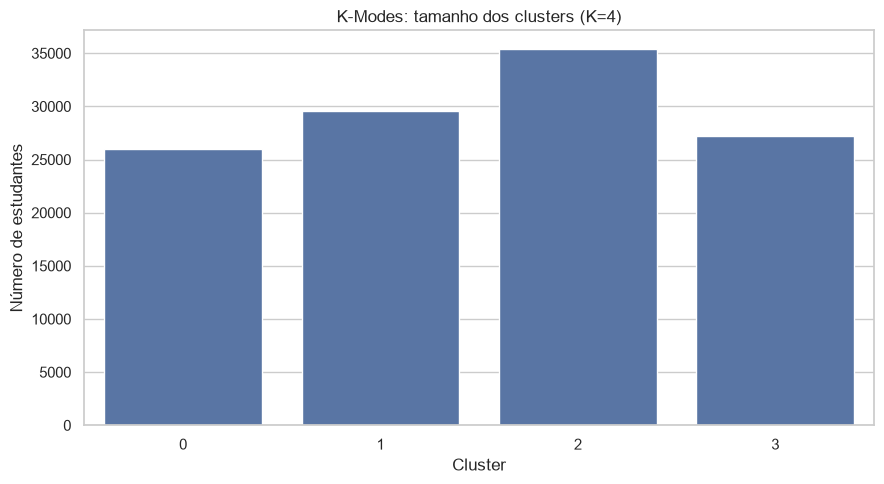


Arquivos CSV salvos com sucesso.


In [14]:

import pandas as pd
import numpy as np
from kmodes.kmodes import KModes
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. DEFINIR O NÚMERO DE CLUSTERS
# ============================================================

K = 4
RANDOM_STATE = 42

# ============================================================
# 2. PREPARAR OS DADOS
# ============================================================

# Considere que seu DataFrame original se chama df.
# X deve conter somente as variáveis utilizadas no clustering.
# Exemplo:
# X = df.copy()

X = X.copy()

# Converter todas as variáveis para categóricas (strings)
X = X.astype("string")

# Tratar valores ausentes como uma categoria explícita
X = X.fillna("AUSENTE")

# Garantir que todas as colunas estejam em formato string
X = X.astype(str)

# Remover colunas constantes, se existirem
colunas_constantes = [
    col for col in X.columns if X[col].nunique() <= 1
]

if colunas_constantes:
    print("Colunas removidas por serem constantes:",
          colunas_constantes)
    X = X.drop(columns=colunas_constantes)

# Verificações
if X.empty:
    raise ValueError("Não há variáveis disponíveis para clustering.")

if len(X) <= K:
    raise ValueError("O número de observações deve ser maior que K.")

print("Número de estudantes:", len(X))
print("Número de variáveis:", X.shape[1])
print("Número de clusters:", K)

# ============================================================
# 3. EXECUTAR O K-MODES
# ============================================================

modelo_kmodes = KModes(
    n_clusters=K,
    init="Huang",
    n_init=5,
    max_iter=100,
    random_state=RANDOM_STATE,
    verbose=1
)

clusters = modelo_kmodes.fit_predict(X)

# Adicionar o cluster a cada estudante
df_resultado = df.loc[X.index].copy()
df_resultado["cluster"] = clusters

# ============================================================
# 4. TAMANHO E DISTRIBUIÇÃO DOS CLUSTERS
# ============================================================

tamanhos = (
    df_resultado["cluster"]
    .value_counts()
    .sort_index()
)

resumo_clusters = pd.DataFrame({
    "cluster": tamanhos.index,
    "n_estudantes": tamanhos.values,
    "percentual": (
        tamanhos.values / len(df_resultado) * 100
    ).round(2)
})

print("\nRESUMO DOS CLUSTERS")
print(resumo_clusters.to_string(index=False))

# ============================================================
# 5. MODAS DE CADA CLUSTER
# ============================================================

# Protótipos: categoria modal de cada variável em cada cluster
modas_clusters = pd.DataFrame(
    modelo_kmodes.cluster_centroids_,
    columns=X.columns
)

modas_clusters.index.name = "cluster"

print("\nMODAS DOS CLUSTERS")
print(modas_clusters.to_string())

# ============================================================
# 6. CUSTO FINAL DO MODELO
# ============================================================

print("\nCUSTO FINAL:", modelo_kmodes.cost_)
print("Número de iterações:", modelo_kmodes.n_iter_)

# ============================================================
# 7. GRÁFICO DO TAMANHO DOS CLUSTERS
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=resumo_clusters,
    x="cluster",
    y="n_estudantes"
)

plt.title(f"K-Modes: tamanho dos clusters (K={K})")
plt.xlabel("Cluster")
plt.ylabel("Número de estudantes")
plt.tight_layout()
plt.show()

# ============================================================
# 8. SALVAR RESULTADOS
# ============================================================

df_resultado.to_csv(
    f"pense2024_kmodes_K{K}_estudantes.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_clusters.to_csv(
    f"pense2024_kmodes_K{K}_resumo.csv",
    index=False,
    encoding="utf-8-sig"
)

modas_clusters.to_csv(
    f"pense2024_kmodes_K{K}_modas.csv",
    encoding="utf-8-sig"
)

print("\nArquivos CSV salvos com sucesso.")
